# 13 · SmartGrid Cyber-Physical Attack dataset

**Utility for the City Brain: medium** · Domain: power / security · Incident types: `power_problem`, fake readings (Guardian)

> Readings of 9 grid controllers (PLCs) and their network traffic in 6 scenarios: normal, false data injection and 4 cyber attacks. It shows what a *fake* power reading looks like.

| | |
|---|---|
| **Source** | IEEE DataPort, DOI 10.21227/symr-bz19 |
| **Licence** | IEEE DataPort terms: not redistributed here |
| **In this repo** | No data. Outputs below were produced on the full download |
| **Get it** | IEEE DataPort (account needed): `SmartGrid-CyberPhysical-Attack-Dataset.zip`, unzip to `Dataset/{scenario}/Physical.csv, Cyber.csv` |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

Scenarios: `benign`, `FDI` (false data injection), `backdoor`, `Bruteforce`, `ransomware`, `reverseshell`.

- `Physical.csv`: `@timestamp`, `PLCID` (1–9), frequency, phase angle, voltages and currents per phase, active / reactive power, breaker status. Numbers use **thousands separators** (`"85,717,736"`).
- `Cyber.csv`: one row per network packet (time, MAC / IP addresses, protocol such as Modbus/TCP, ports, length).

In [2]:
ROOT = Path(path('power/smartgrid-attack/Dataset'))
def phys(s):
    x = pd.read_csv(ROOT / s / 'Physical.csv', thousands=',')
    x['t'] = x['@timestamp'] - x['@timestamp'].min()
    return x
ben, fdi = phys('benign'), phys('FDI')
print(len(ben), 'benign rows ·', len(fdi), 'FDI rows'); ben.head()

99904 benign rows · 99956 FDI rows


,@timestamp,PLCID,Freq,Theta,V_A,V_B,V_C,I_A,I_B,I_C,ActivePower,ReactivePower,BreakerStatus,t
0,1.678467e+09,2,59.992,6.143,85732060,85731390,85732296,393142.340,393137.800,393139.94,93783000000000,3.779937e+13,1,0.000
1,1.678467e+09,6,59.992,6.031,92463920,92463050,92463930,401129.100,401124.880,401126.10,-103271750000000,-4.146730e+13,1,0.148
2,1.678467e+09,1,59.992,6.143,85758120,85757450,85758344,1658047.800,1658031.400,1658046.10,420575800000000,7.126327e+13,1,0.199
3,1.678467e+09,5,59.992,6.143,85717736,85717050,85717950,85.745,85.744,85.74,-22048913000,-5.787484e+06,1,0.914
4,1.678467e+09,3,59.992,6.142,85638050,85637370,85638270,1596385.600,1596368.100,1596377.40,-384160160000000,-1.436257e+14,1,1.083


## 2. Normal is almost perfectly flat

In [3]:
cols = ['Freq', 'V_A', 'I_A', 'ActivePower']
(ben.groupby('PLCID')[cols].std() / ben.groupby('PLCID')[cols].mean().abs() * 100).round(4).head()   # coefficient of variation, %

,Freq,V_A,I_A,ActivePower
PLCID,,,,
1,0.0,0.0003,0.0003,0.0000
2,0.0,0.0003,0.0004,0.0001
3,0.0,0.0003,0.0004,0.0000
4,0.0,0.0003,0.0185,0.0274
5,0.0,0.0003,0.0044,0.0055


## 3. False data injection: a sudden step on a few devices

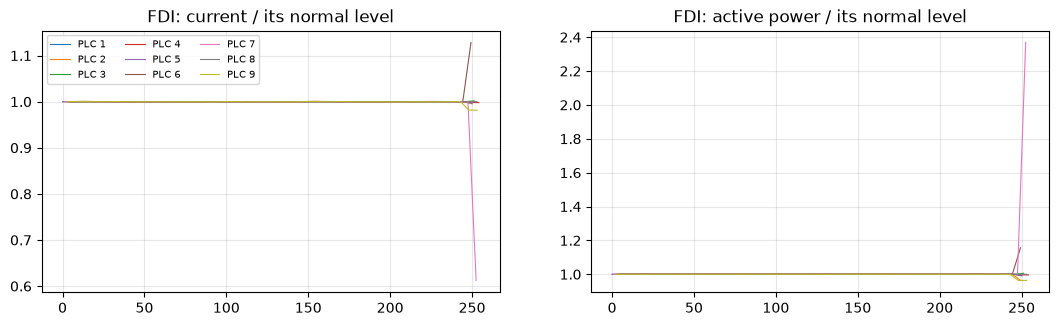

,I_A change % (last 10 s),ActivePower change % (last 10 s)
PLCID,,
1,-0.5,-0.9
2,-0.4,-3.5
3,0.0,0.0
4,-0.2,-0.4
5,-0.0,-0.0
6,0.0,-0.0
7,-19.4,68.4
8,-0.0,-0.0
9,-1.9,-3.6


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for p, g in fdi.groupby('PLCID'):
    ax[0].plot(g.t, g.I_A / g.I_A.iloc[:len(g) // 2].median(), lw=.8, label=f'PLC {p}')
    ax[1].plot(g.t, g.ActivePower / g.ActivePower.iloc[:len(g) // 2].median(), lw=.8)
ax[0].set_title('FDI: current / its normal level'); ax[1].set_title('FDI: active power / its normal level')
ax[0].legend(fontsize=7, ncol=3); plt.show()
first, last = fdi[fdi.t < fdi.t.max() * .5], fdi[fdi.t > fdi.t.max() - 10]
chg = (last.groupby('PLCID')[['I_A', 'ActivePower']].median() / first.groupby('PLCID')[['I_A', 'ActivePower']].median() - 1) * 100
chg.round(1).rename(columns=lambda c: c + ' change % (last 10 s)')

In [5]:
def cyber(s):
    x = pd.read_csv(ROOT / s / 'Cyber.csv', low_memory=False, on_bad_lines='skip')
    return x
summary = {}
for s in ['benign', 'Bruteforce', 'backdoor', 'ransomware']:   # FDI's Cyber.csv has a shifted header
    c = cyber(s); proto = [k for k in c.columns if 'Protocol' in k]
    summary[s] = c[proto[0]].value_counts(normalize=True).head(3).mul(100).round(0).to_dict() if proto else {}
pd.Series(summary).to_frame('top protocols (% of packets)')

,top protocols (% of packets)
benign,"{'TCP': 77.0, 'Modbus/TCP': 20.0, 'HTTP': 2.0}"
Bruteforce,"{'TCP': 79.0, 'Modbus/TCP': 17.0, 'HTTP': 3.0}"
backdoor,"{'TCP': 76.0, 'Modbus/TCP': 20.0, 'HTTP': 2.0}"
ransomware,"{'TCP': 77.0, 'Modbus/TCP': 20.0, 'HTTP': 2.0}"


FDI is **invisible on the network** (traffic looks normal) and the other attacks are **invisible physically**: detecting both needs both views (the Guardian's job).

## 4. What it means for the City Brain

| Use | How |
|---|---|
| **Scenarios** | The "Guardian rejects the sensor → no incident" test: a sudden step on one or a few devices (table above: PLC 7) while everything else, including the network, looks normal |
| **Detect** | Benign variance is ≈ 0, so "3 × usual variation" fires on noise: add a **minimum-variation floor** (1–2 % of mean) to the 3σ rule |
| **Guardian** | Benchmark for the security layer (physical + cyber views) |

**Limits:** simulated steady state (useless as a normal load curve, see notebook 04); no label column or attack start time; odd units; the FDI cyber file has a shifted header.